# RehaPiano: comparing healthy and sick participants
## Force control, faster oscillations and possible tremor
**Weekly research task · 11 October 2026 · English report**

We extend the existing Balanced Force notebooks to the entire indexed cohort. The deliverable is a set of reproducible, interpretable measurements for each person, with left and right hands kept separate.

**Main conclusion:** the measurements describe differences between the healthy and sick groups, but cannot diagnose a person by themselves. Faster oscillations are larger in the sick group on average, with substantial overlap. Age and differences in the recording procedure can also explain part of the separation. The numerical results below come directly from the supplied recordings.

## 1. Who is healthy and who is sick?
The report uses two clear presentation labels throughout:

- **Sick group:** all 48 people recruited into the patient group.
- **Healthy group:** 76 people from the control recruitment group who reported no relevant health problem in the available questionnaire and had an unambiguous matching ID.

For traceability, the source files call these groups the **patient cohort** and the **reference cohort**. Those are recruitment labels. The report's word “healthy” means **questionnaire-screened for this exploratory comparison**, not physician-confirmed healthy. Exact diagnoses, clinical tremor assessments and medication information for the sick group are not available in the analysis index.

The archive contains another 14 people recruited into the reference cohort who are not used as healthy examples in the binary comparison: 11 reported a relevant health problem, two had no usable matching questionnaire and one had a duplicated questionnaire ID. Their feature rows remain in the exported dataset.

## 2. Data source and reproducible run
The existing project notebooks are unchanged. The pipeline reads the JSON result files directly, using the timestamp format verified in `task_1.ipynb`. It does not rely on the original converter's floating-point timestamp decoding.

The local archive contains the September 2026 batch. Every archive path is already extracted with a matching size; no newer remote recording source was supplied. This analysis uses the local data and a fresh snapshot of the supplied questionnaire, introductory document and research protocol.

The two selected EXACT_FORCE scenario IDs are inherited from the earlier comparisons. The second control-group EXACT_FORCE step is excluded because its equivalence is not confirmed. A different step ID perfectly identifies the two recruitment groups in this selected data, so protocol-independent validation is not possible here.

Set `RECOMPUTE = True` to rebuild all derived outputs. With the default `False`, the already computed outputs are loaded; missing outputs trigger computation.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
import analysis
import extensions

HERE = Path.cwd()
PROJECT_ROOT = HERE.parents[1] / "data"  # repository data folder containing RehaPiano/
RECOMPUTE = False
if RECOMPUTE or not (HERE / "outputs/run_summary.json").exists():
    analysis.main(PROJECT_ROOT)
if RECOMPUTE or not (HERE / "outputs/participant_features.csv").exists():
    extensions.enrich(PROJECT_ROOT)
OUT = HERE / "outputs"
FIG = HERE / "figures"
def table(name):
    return pd.read_csv(OUT / (name + ".csv"), dtype={"patient_id": str})
def figure(name):
    display(Image(filename=str(FIG / (name + ".png"))))
pd.set_option("display.max_columns", 14)
pd.set_option("display.precision", 6)
summary = json.loads((OUT / "run_summary.json").read_text())
manifest = table("recording_manifest")
labels = table("participant_labels")
features = table("participant_hand_features_primary")
hands = table("hand_windows")
quality = table("recording_quality")
display(pd.DataFrame({"Measure": ["Participants", "Selected sessions", "Repetitions", "Processing failures", "Divergent raw copies"],
                      "Count": [summary["participants"], summary["sessions"], summary["quality_iterations"], summary["processing_errors"], summary["divergent_files"]]}))
group_overview = pd.DataFrame({
    "Report label": ["Sick group", "Healthy group", "Other control-recruitment records"],
    "People": [48, 76, 14],
    "Used in healthy-vs-sick comparison": ["Yes", "Yes", "No"]
})
display(group_overview)

,Measure,Count
0,Participants,138
1,Selected sessions,173
2,Repetitions,692
3,Processing failures,0
4,Divergent raw copies,0


,Report label,People,Used in healthy-vs-sick comparison
0,Sick group,48,Yes
1,Healthy group,76,Yes
2,Other control-recruitment records,14,No


## 3. From the raw recording to a usable force signal
1. Decode Base64 → zlib → data-only pickle → 72-byte packets: unsigned 64-bit millisecond timestamp plus sixteen float32 channels. Class loading is disabled.
2. Retain channels 0–4 and 8–12, following the existing notebooks' hand mapping. Reserved channels are excluded; anatomical finger order remains unverified.
3. Process repetitions separately. Reject backward timestamps. Average duplicate timestamps and interpolate only short supported gaps. Split timestamp gaps over 50 ms; reject a channel with excessive or long missing data rather than filling across it.
4. Create a 1 ms time grid and use polyphase anti-alias filtering to reduce to 100 Hz. The output Nyquist frequency is 50 Hz, comfortably above the requested 15 Hz limit. Resampling does not create new physical information.
5. Keep windows within 3–15 seconds, with margins from segment edges. The primary windows are 3–8 and 8–13 seconds. Later we repeat the analysis using only 8–13 seconds to check force-adjustment transients.

The older introductory document describes 70 Hz hardware. The observed stream is about 1,000 packets/s; this is not proof of the ADC rate or independence of successive values. Confirm the acquisition chain before physiological claims. Forces remain in relative device units.

In [2]:
display(quality[["duration_s", "effective_packet_rate_hz", "duplicate_timestamps", "max_gap_ms", "nonfinite_fraction"]].describe().loc[["count", "min", "50%", "max"]])
display(Markdown(f"**Method checks:** {summary['method_checks']['status']}. " + "; ".join(summary['method_checks']['checks']) + "."))

,duration_s,effective_packet_rate_hz,duplicate_timestamps,max_gap_ms,nonfinite_fraction
count,692.000,692.000000,692.0,692.0,692.000000
min,16.003,999.688299,2890.0,3.0,0.000000
50%,16.029,1000.561220,3886.5,5.0,0.000467
max,16.044,1009.669370,5206.0,11.0,0.009422


**Method checks:** passed. known sine amplitudes and frequency; opposite-phase cancellation; unused hand exclusion; zero-power undefined frequency; filter separation; large-gap splitting; timestamp reset rejection; jitter and NaN resampling; invalid channel isolation.

## 4. Separating slow control from faster oscillations
| Frequency range | Output | Interpretation |
|---|---|---|
| 0.2 to below 3 Hz | Slow-band RMS | Force-control variation, drift and other slow movement |
| 3 to below 4 Hz | Boundary-band RMS | Ambiguous frequencies retained for inspection |
| 4 through 15 Hz | Candidate-tremor RMS | Faster oscillations; involuntary origin is unconfirmed |
| 4 to below 12 Hz / 12 through 15 Hz | Sub-band RMS | Distinguishes lower and upper parts of the faster band |

This partition is a **working hypothesis**, not a validated source separation. The low-frequency range can contain involuntary movement, and abrupt voluntary corrections can produce high-frequency energy. A force-control experiment found contributions from several mechanisms below 3 Hz. [Force-control experiment](https://pmc.ncbi.nlm.nih.gov/articles/PMC3202062/).

For a visual decomposition we use fourth-order Butterworth low-pass (<3 Hz) and band-pass (4–15 Hz) filters applied forward and backward to the full repetition, before cropping. Their effective response is squared and their boundaries are gradual. They are not a perfect two-component reconstruction: ambiguous frequencies and residual noise remain.

**Read this plot carefully:** the patient's abrupt force drop near 3.5 s produces a burst in the filtered faster component. Such filter response is not, by itself, evidence of tremor. The low-pass trace includes the held-force level; the slow PSD feature below excludes DC and linear trend.

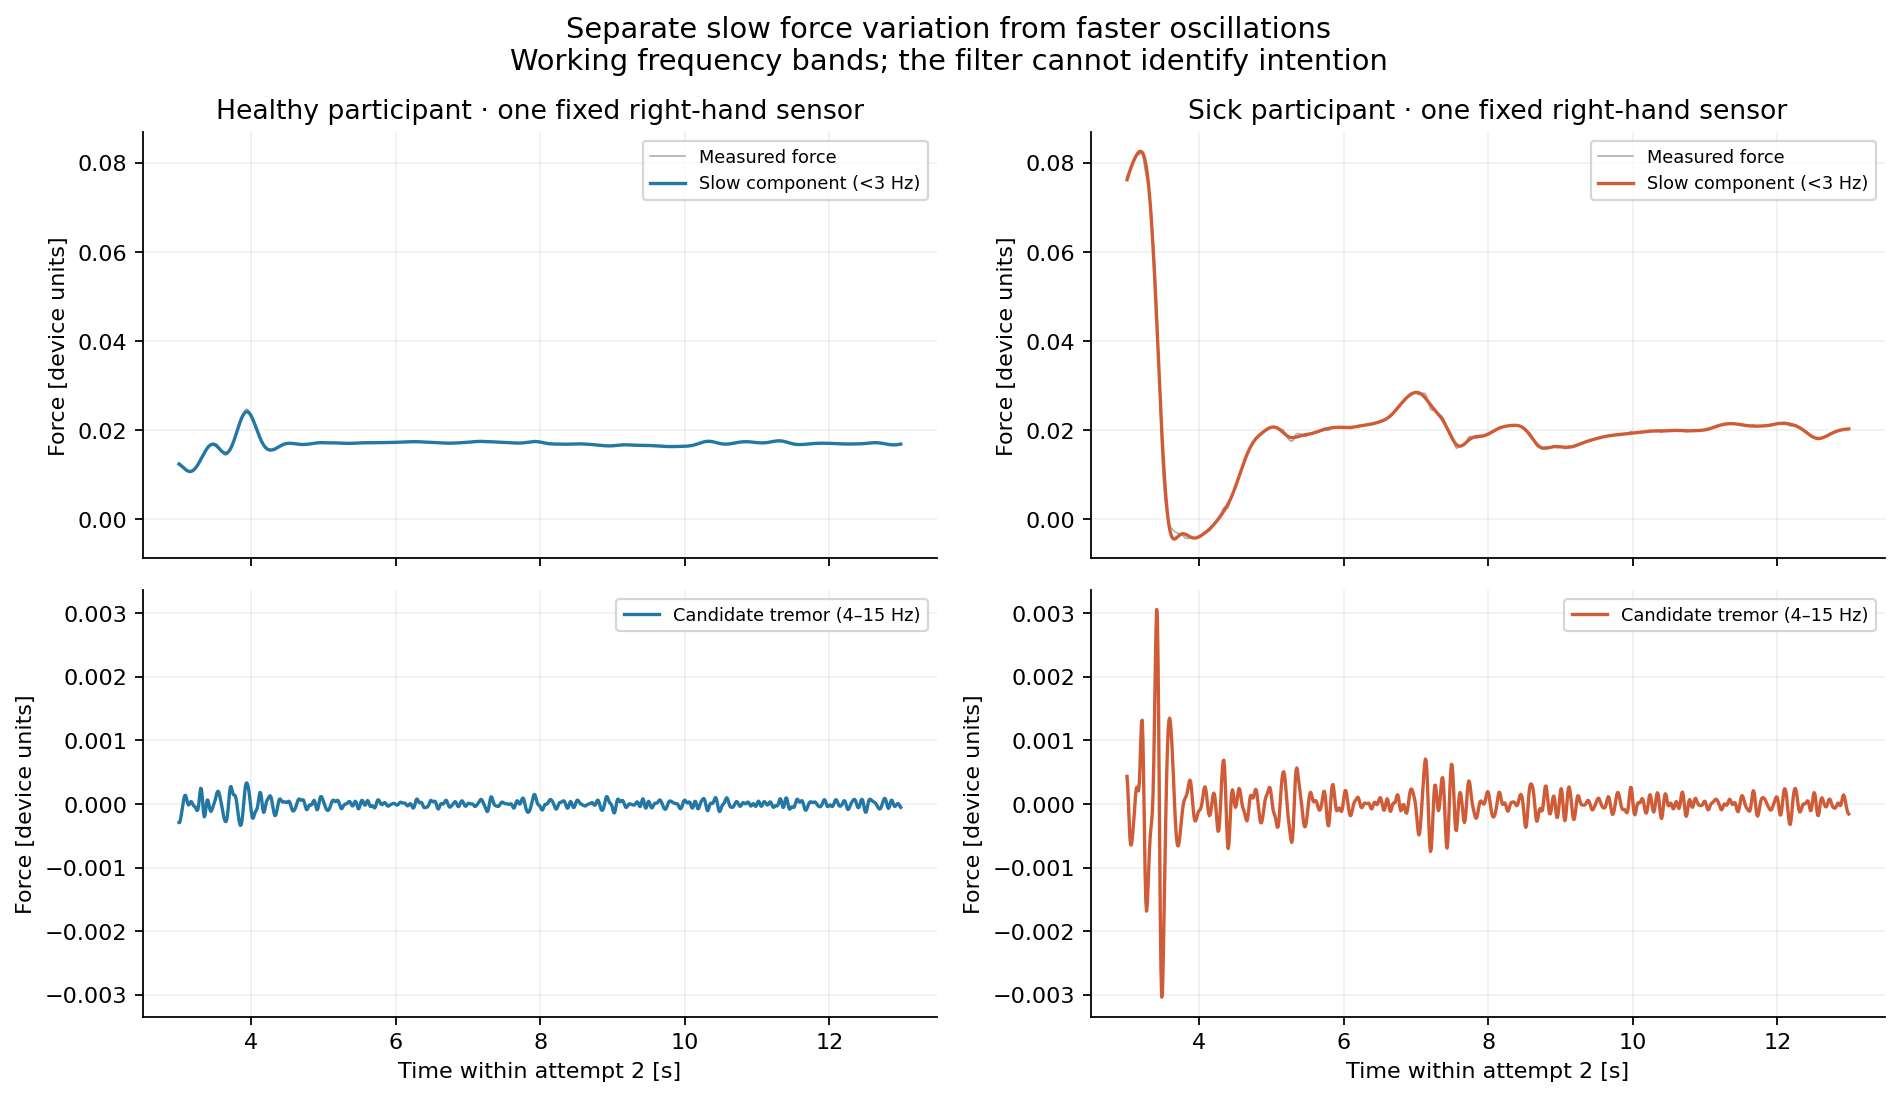

In [3]:
figure("01_decomposition")

## 5. Numbers calculated for each person
PSD is computed from each complete window using linear detrending and a Hann taper, without zero padding. A band power is `sum(PSD × Δf)` over its frequency bins. RMS is `sqrt(band power)`. It is a fluctuation amplitude, not the mean force or a peak-to-peak measurement. [PSD definition](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.periodogram.html).

| Feature | Definition / use |
|---|---|
| `slow_rms`, `tremor_rms` | Amplitude of the slow and candidate-tremor bands, in device units |
| `centroid_hz` | PSD-weighted mean frequency within 4–15 Hz |
| `spectral_spread_hz` | PSD-weighted standard deviation of frequency within 4–15 Hz |
| `peak_hz` | Highest-power bin within 4–15 Hz; a peak exists even in noise |
| `tremor_rms_window_sd` | Sample SD of band RMS across valid windows for that person and hand |
| `centroid_window_sd_hz`, `peak_window_sd_hz` | Temporal/repetition/session variability of frequency descriptors |
| `tremor_fraction` | 4–15 Hz power divided by the sum of slow, boundary and 4–15 Hz powers |
| `valid_windows`, `usable_fraction` | Amount of evidence retained after hand-use screening |

**Avoid cancellation:** calculate each finger's PSD, then average the eligible finger PSDs within a hand. Opposite-phase oscillations can cancel in the mean waveform; averaging powers preserves them. The resulting hand RMS describes an average eligible finger, not total grip force.

**One person is one statistical unit:** average windows within repetition → repetitions within session → sessions within person, with equal weights at each level. Left/right hands remain separate. Window SD pools valid windows and is descriptive variability, not a confidence interval. The machine-readable one-row-per-person file is `outputs/participant_features.csv`.

In [4]:
columns = ["patient_id", "hand", "slow_rms", "tremor_rms", "centroid_hz", "spectral_spread_hz", "tremor_rms_window_sd", "valid_windows"]
example = features.loc[features.patient_id.isin(["992601", "UQIS-DXIH", "992612", "ILHC-BZCP"]), columns].copy()
example.insert(0, "Group", example.patient_id.map({"992601":"Healthy", "992612":"Healthy", "UQIS-DXIH":"Sick", "ILHC-BZCP":"Sick"}))
example = example.rename(columns={"patient_id":"ID", "hand":"Hand", "slow_rms":"Slow-change amplitude", "tremor_rms":"Faster-oscillation amplitude", "centroid_hz":"Typical frequency [Hz]", "spectral_spread_hz":"Frequency spread [Hz]", "tremor_rms_window_sd":"Amplitude variability", "valid_windows":"Usable windows"})
display(example)
display(Markdown(f"**Exported:** {len(table('participant_features'))} participant rows; {len(features)} participant–hand rows at the primary window length."))

,Group,ID,Hand,Slow-change amplitude,Faster-oscillation amplitude,Typical frequency [Hz],Frequency spread [Hz],Amplitude variability,Usable windows
0,Sick,UQIS-DXIH,left,0.005554,0.000280,6.906935,2.219172,0.000294,16
1,Sick,UQIS-DXIH,right,0.005678,0.000297,6.890125,1.986960,0.000248,16
26,Sick,ILHC-BZCP,left,0.008922,0.000484,6.027515,1.985202,0.000490,16
27,Sick,ILHC-BZCP,right,0.006406,0.001352,4.968551,1.487556,0.000653,16
252,Healthy,992601,left,0.006042,0.000300,6.469194,2.399533,0.000566,8
253,Healthy,992601,right,0.006265,0.000290,6.386745,2.268813,0.000495,8
274,Healthy,992612,left,0.000968,0.000126,6.587055,2.933228,0.000083,8
275,Healthy,992612,right,0.001028,0.000155,6.558190,2.471615,0.000109,8


**Exported:** 138 participant rows; 276 participant–hand rows at the primary window length.

## 6. When one hand is barely used
A finger is eligible when its data are finite, its median absolute force is at least 0.002 units, at least 20% of samples exceed that floor, it is not effectively constant (SD > 10⁻⁷), and fewer than 1% of samples are at or beyond the nominal ±1 bounds.

A hand must have an eligible finger, sufficient absolute level, and at least 10% of the stronger hand's level. The hand-level measure is the root mean square of the five per-finger median absolute forces. These are explicit **heuristics**, not calibrated contact or impairment tests. Offsets can mimic contact, and very unequal hands can reflect the task rather than non-use.

Flagged windows yield missing features, never zero tremor. Participants with at least four valid windows for a hand receive a usable summary; smaller numbers are marked limited. A wholly unassessable hand would remain in the export with missing feature values.

,patient_id,hand,iteration,start_s,force_level,relative_hand_level,reason
190,3OUS-NI9J,left,2,3.0,0.015624,0.092083,low_relative_force
569,XT2X-WLNW,right,1,3.0,0.006767,0.054849,low_relative_force
9138,992603,left,1,8.0,0.003889,0.080198,low_relative_force


**3 of 2768 primary hand-windows flagged.** All 276 participant–hand summaries retain at least four valid windows. This does not prove that every hand was used normally.

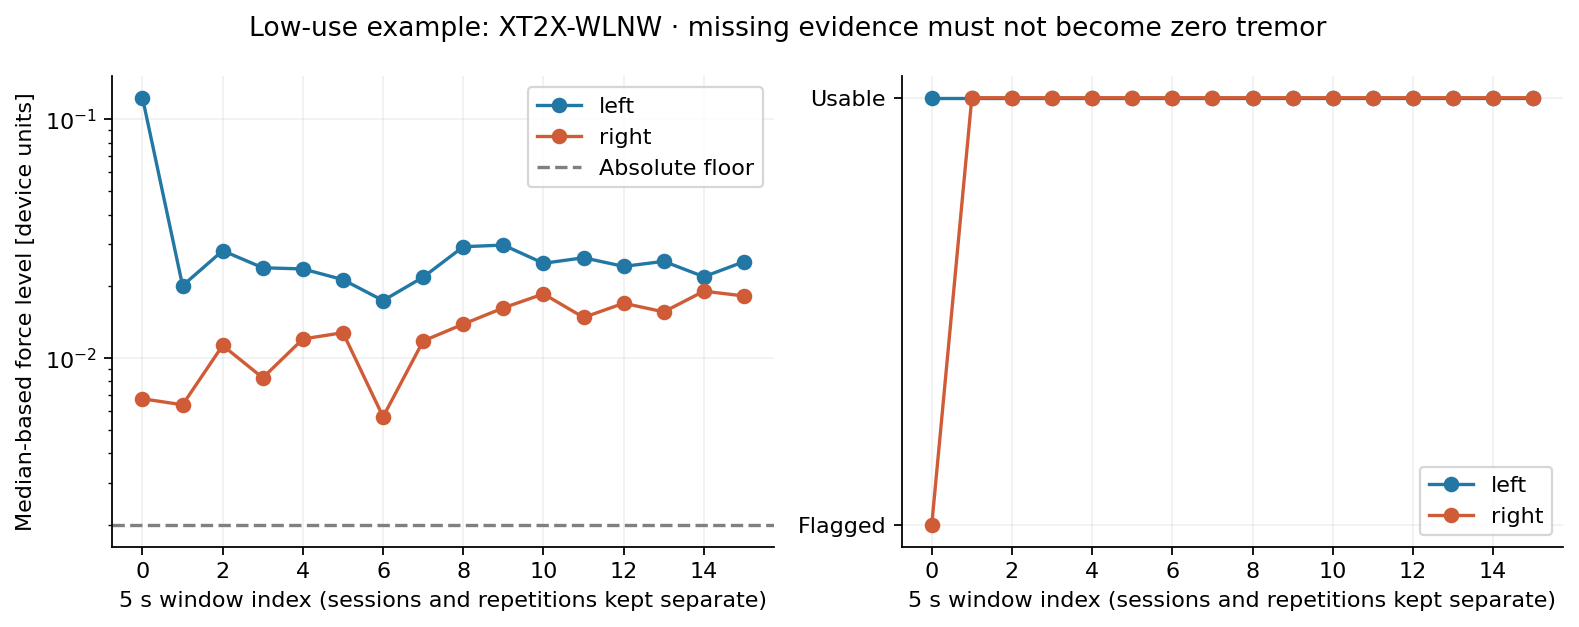

,floor,relative_threshold,mean,size
0,0.001,0.05,1.000000,2768
1,0.001,0.10,0.998916,2768
2,0.001,0.20,0.993136,2768
3,0.002,0.05,1.000000,2768
4,0.002,0.10,0.998916,2768
5,0.002,0.20,0.993136,2768
6,0.005,0.05,0.990968,2768
7,0.005,0.10,0.990246,2768
8,0.005,0.20,0.987717,2768


In [5]:
flagged = hands[(hands.window_s == 5) & ~hands.usable]
display(flagged[["patient_id", "hand", "iteration", "start_s", "force_level", "relative_hand_level", "reason"]])
display(Markdown(f"**{len(flagged)} of {summary['primary_windows']} primary hand-windows flagged.** All 276 participant–hand summaries retain at least four valid windows. This does not prove that every hand was used normally."))
figure("06_low_use_hand")
display(table("activity_sensitivity_summary"))

Across the tested activity thresholds, the retained-window fraction ranges from approximately 98.8% to 100%. This checks sensitivity of **screening counts**; it does not validate the thresholds or recompute all feature values for each setting. The highlighted example is selected by its low hand-force ratio, not its tremor magnitude.

## 7. Main example: a healthy participant and a sick participant
This section explicitly compares one **healthy participant** with one **sick participant**. The healthy participant belongs to the reference cohort and reported no condition affecting hand strength or coordination. The sick participant belongs to the patient cohort. We know these groups from the dataset and questionnaire; we did not diagnose them from the graph.

The identifiers are kept here in the description rather than in the figure titles:

- **Healthy participant:** ID `992601`.
- **Sick participant:** ID `UQIS-DXIH`.

These are the same recordings used in `task_1.ipynb`, using repetition 2. The pair was not selected to maximize separation. The patient's exact diagnosis and clinical tremor status are not available in the analysis table.

The 3/5/10 s demonstration windows share the same 3 s start. Bin spacings are 0.333/0.2/0.1 Hz. The Hann taper makes effective peak resolution broader than one bin. Spectra use shared axes.

The spectrogram uses 2 s windows, a 0.2 s hop, linear detrending, and one shared colour scale. It averages eligible-finger powers for each hand. Overlapping spectrogram columns are correlated, not independent samples.

**How to read the spectrogram:**

- Left column = healthy participant; right column = sick participant.
- Top row = left hand; bottom row = right hand.
- Horizontal position = time; vertical position = frequency.
- Brighter colour = stronger oscillation.
- Below 3 Hz = mostly slow force control; 3–4 Hz = uncertain boundary; 4–15 Hz = faster oscillations that may contain tremor.

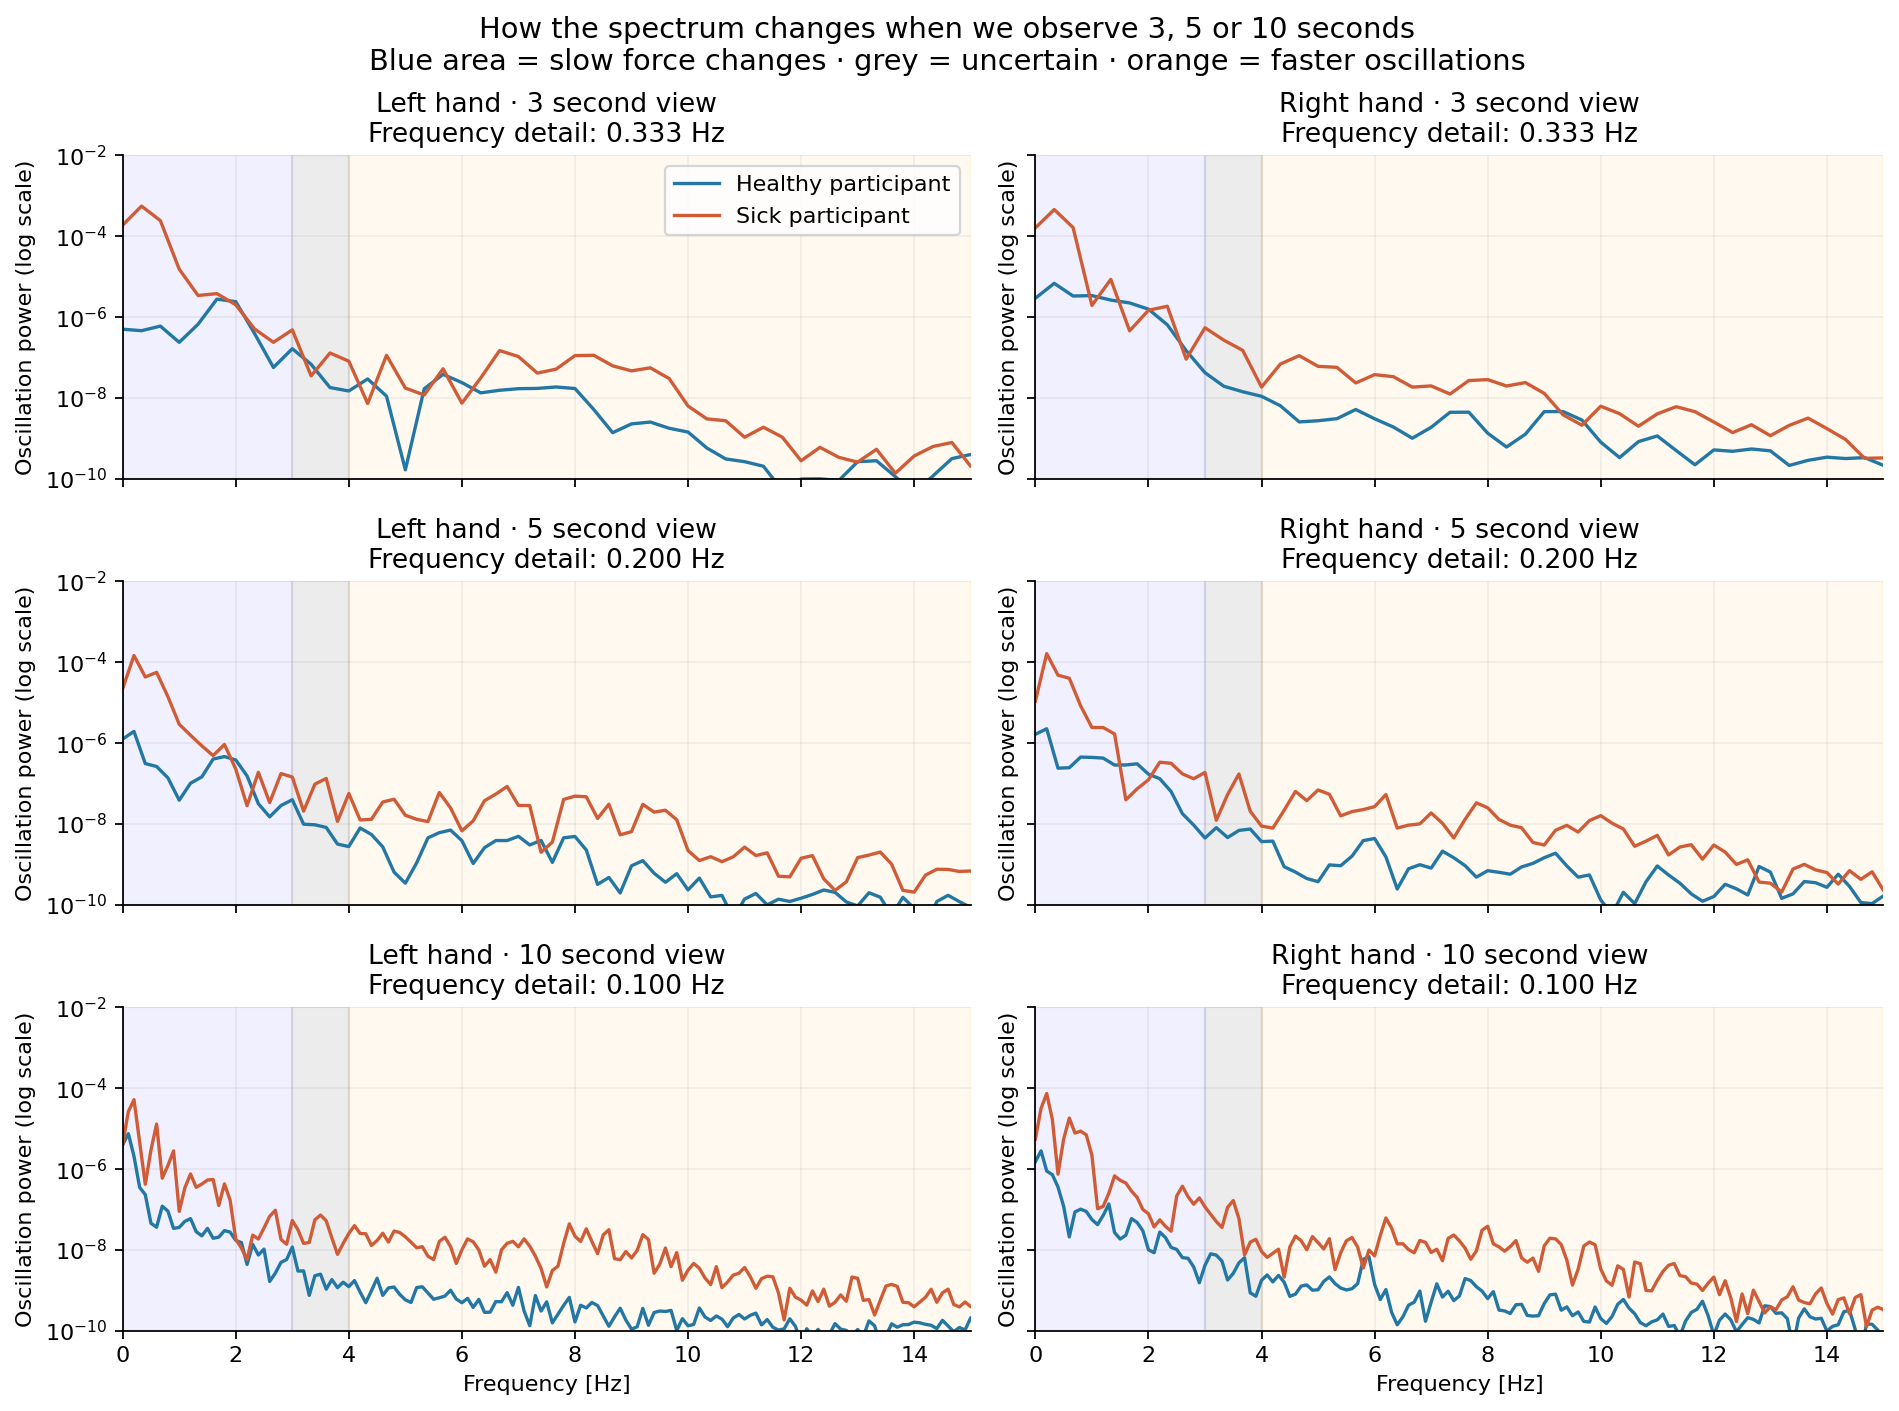

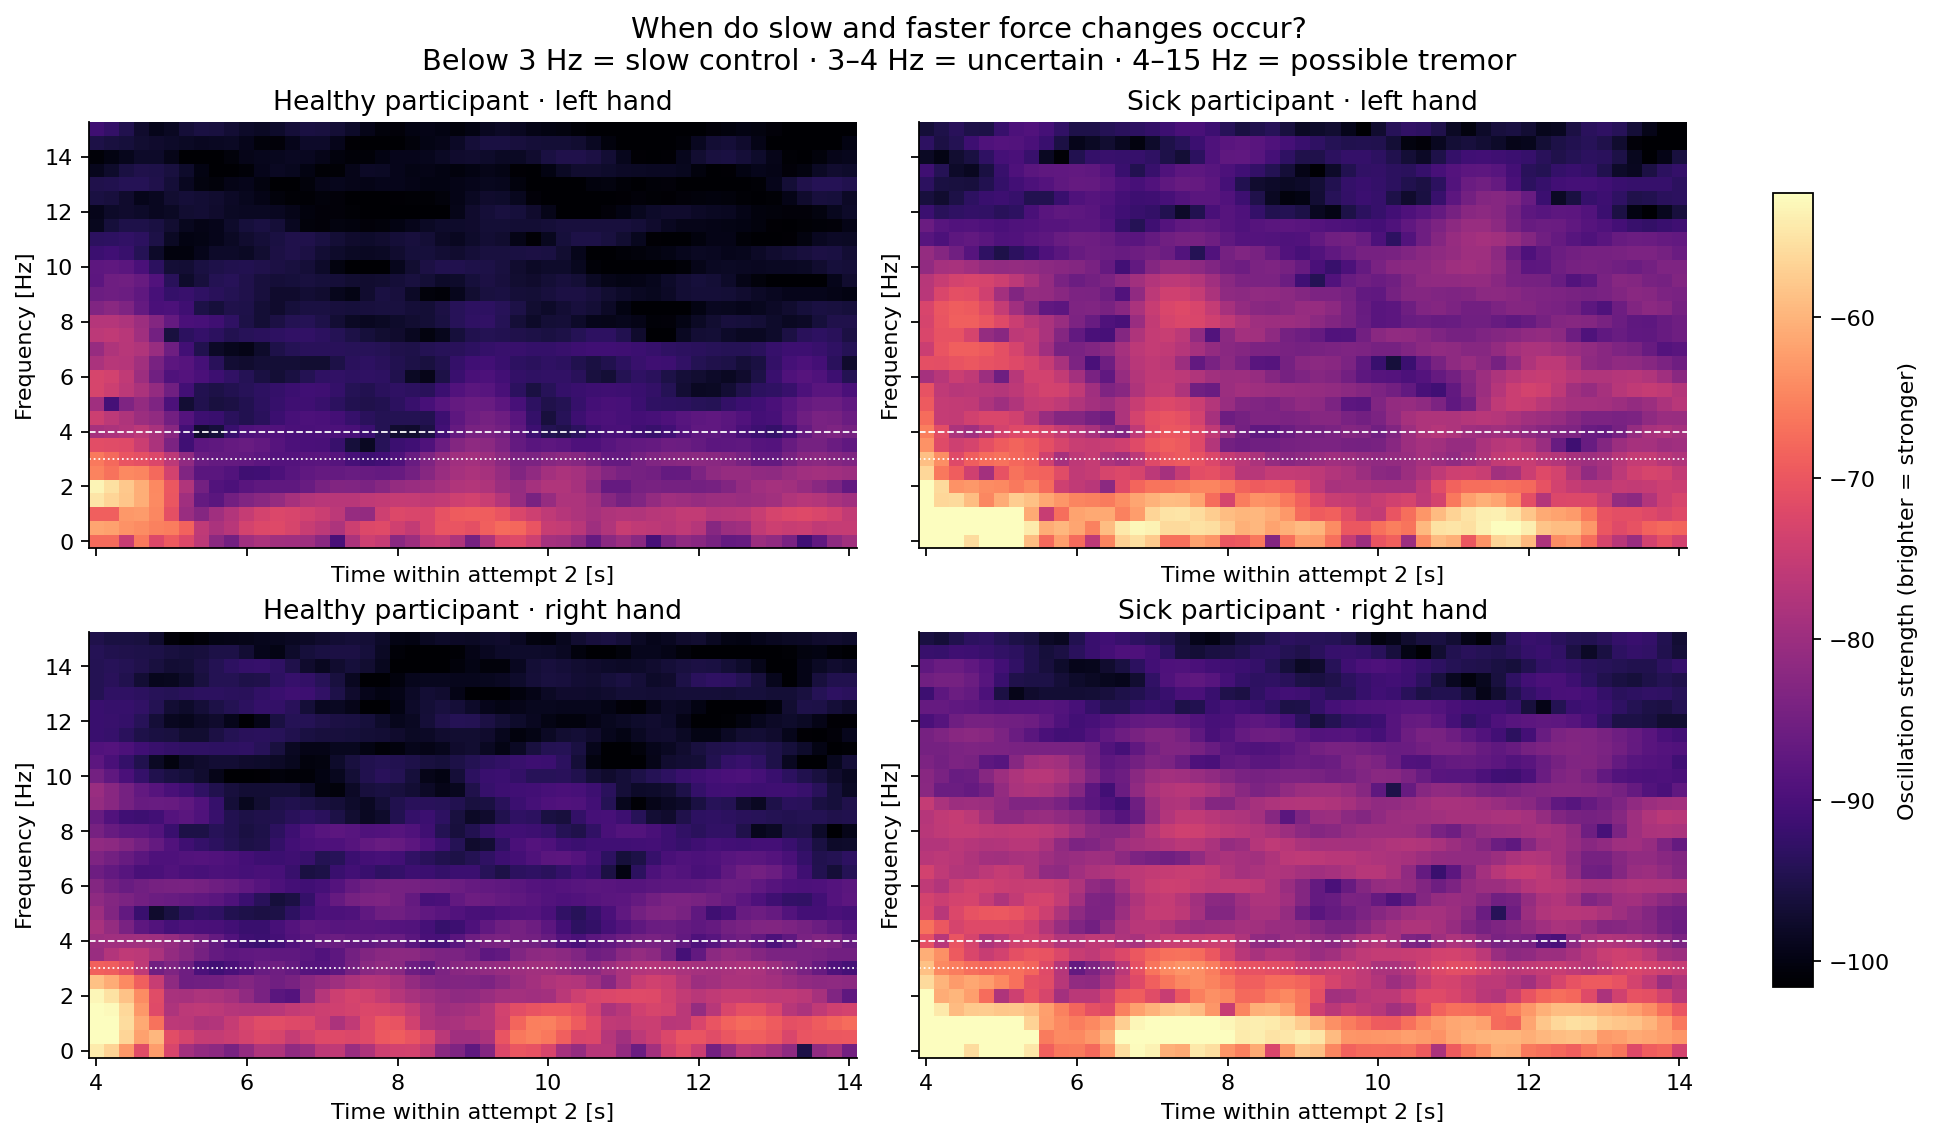

In [6]:
figure("02_window_comparison")
figure("03_spectrograms")

In this particular repetition, the **sick participant** is brighter across a broad range of frequencies. That means more force variation, but it does not by itself prove tremor. Both people contain strong slow components and changes over time, and broadband bursts can be caused by force corrections.

Across **all indexed sessions and repetitions**, the healthy and sick participants in this pair have similar average 4–15 Hz RMS values. We therefore know who is healthy and who is sick from the dataset labels, but this particular spectrogram alone does not separate them reliably.

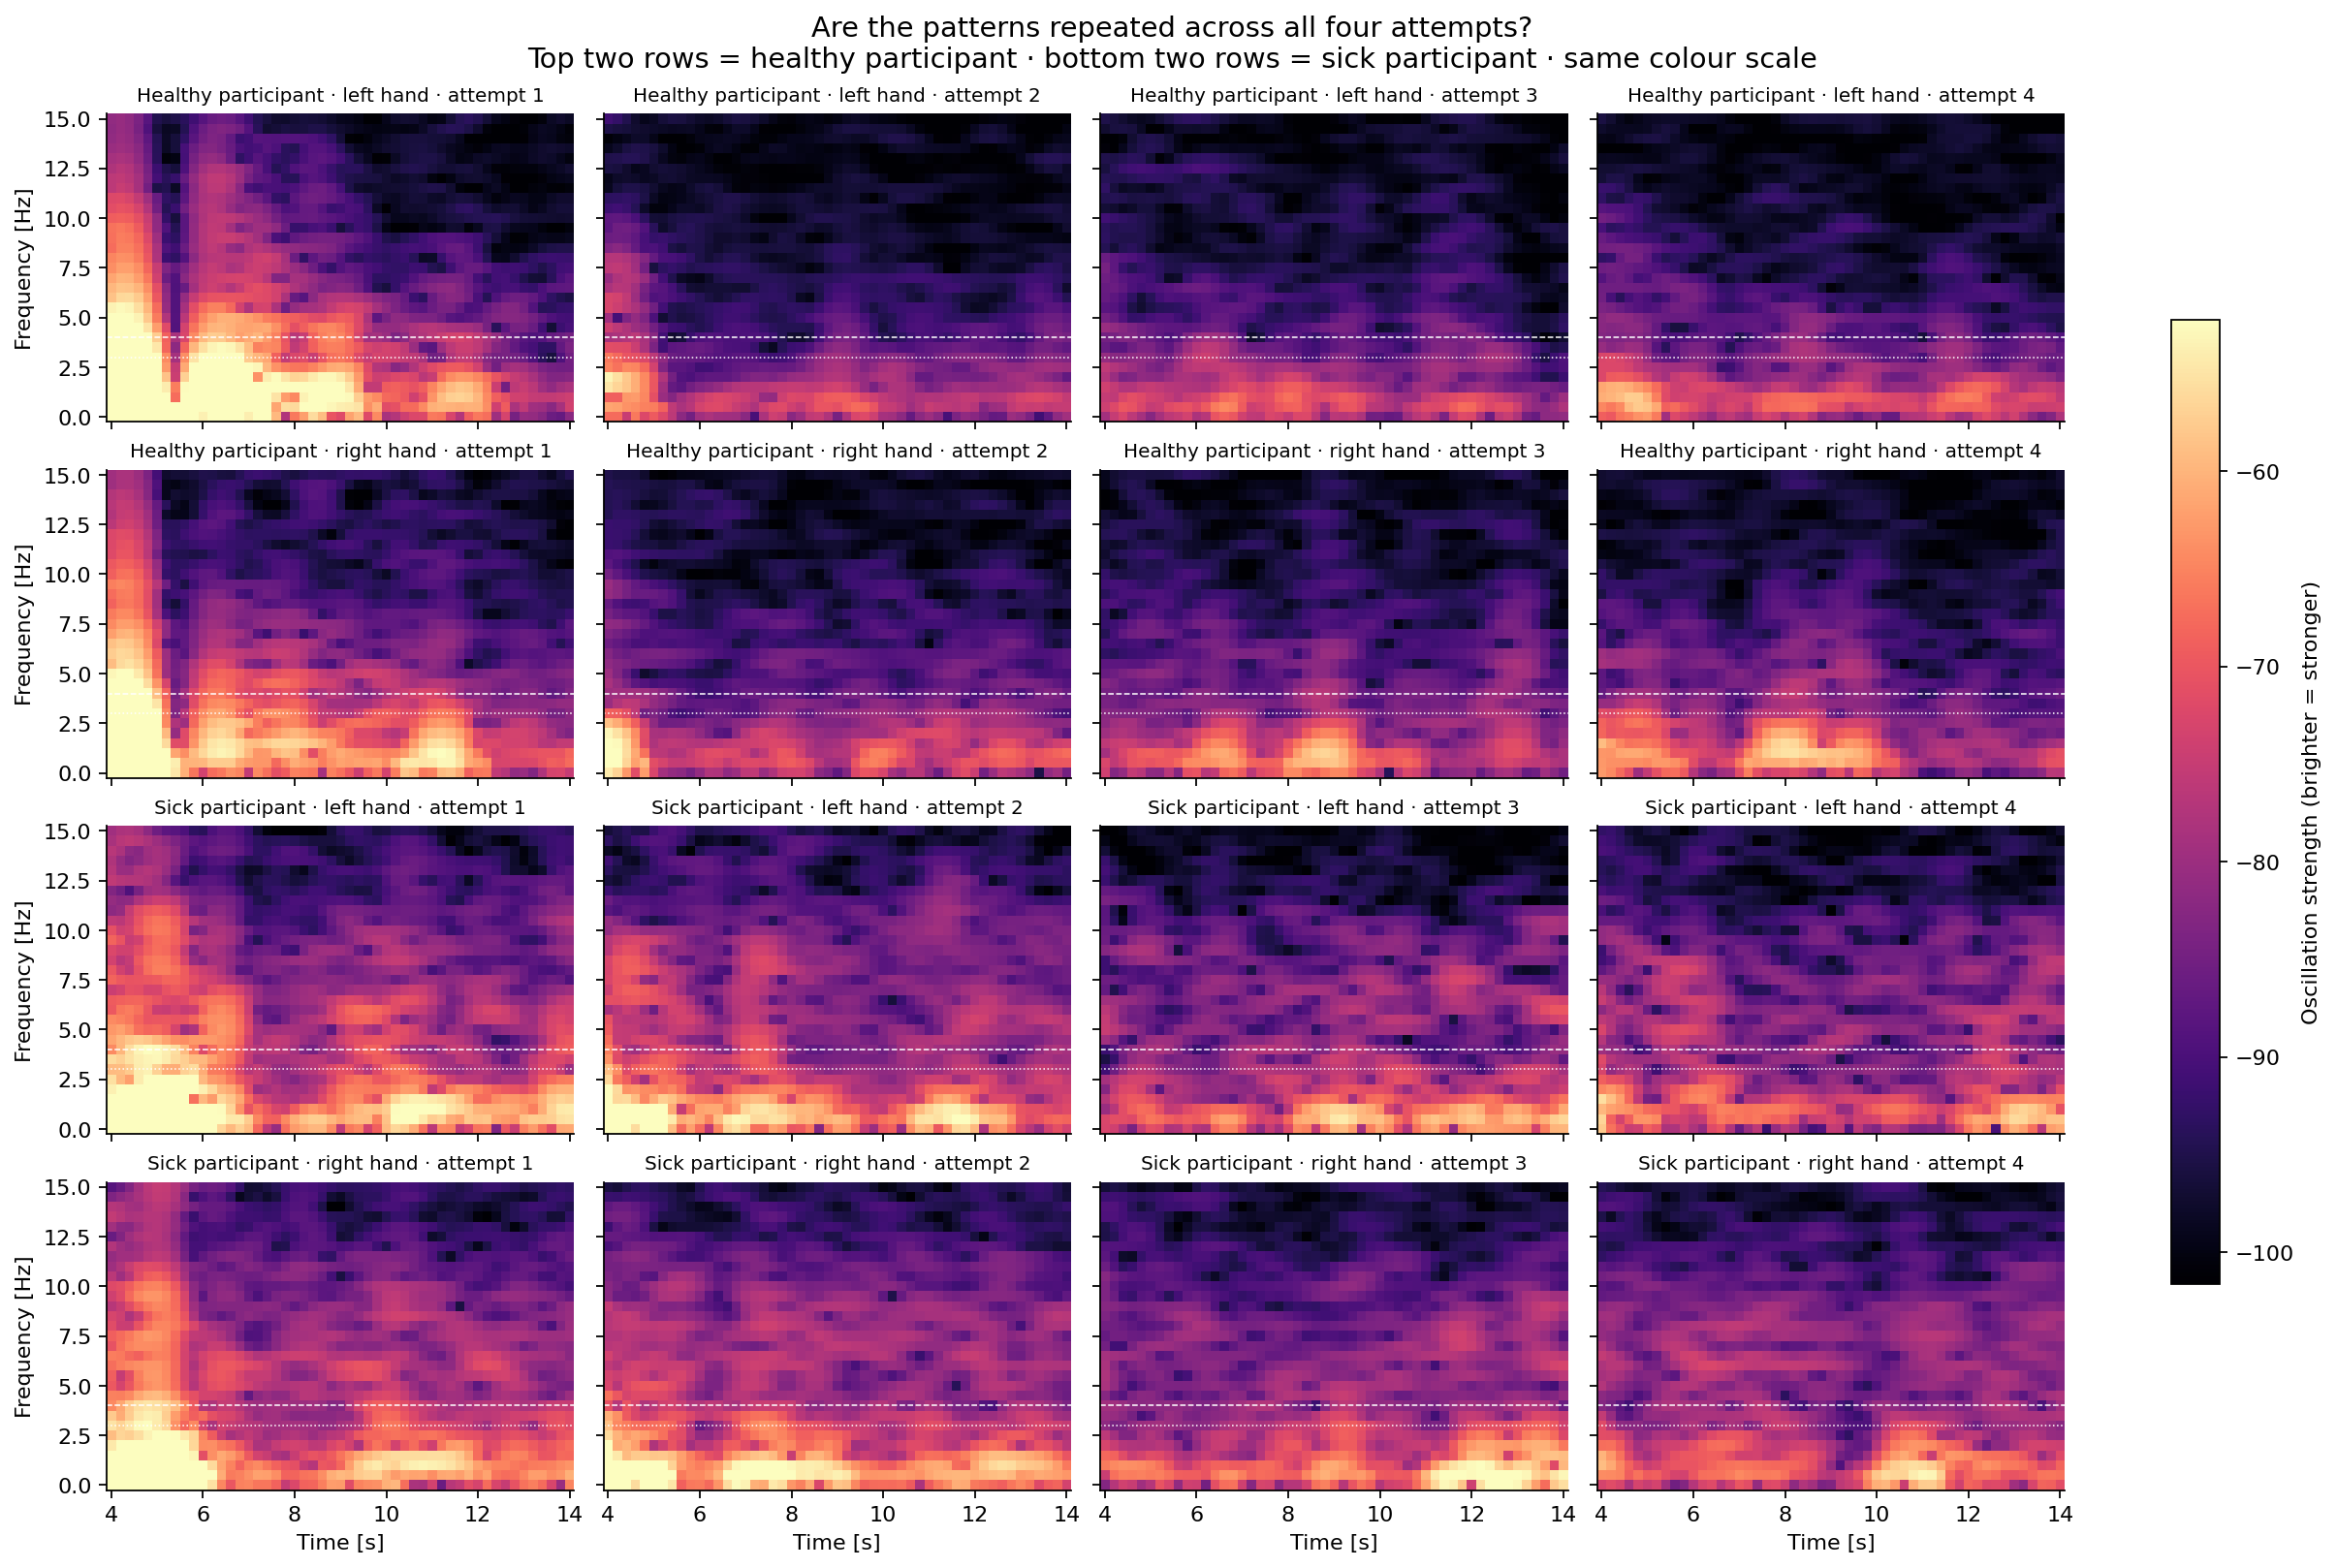

In [7]:
figure("04_all_repetitions")

## 8. Clear teaching example: a healthy participant and a sick participant
This second example also contains one **healthy participant** and one **sick participant**:

- **Healthy participant:** ID `992612`.
- **Sick participant:** ID `ILHC-BZCP`.

The earlier `fourier_exact_force.ipynb` selected the sick participant because of prominent oscillations and selected the healthy participant for similar age and sex. The IDs are kept in this description and the figure uses only the health labels. This is a useful teaching example, but it is not an unbiased validation pair.

Channel 10 shows a peak for the sick participant at approximately **4.0–4.4 Hz** across the four repetitions, with a visible ridge. The healthy participant also has a highest spectral bin, but its amplitude is much lower. This illustrates why repeatability, amplitude and the spectrogram should be read together. The dataset tells us which participant belongs to each group; the graph does not establish a specific diagnosis.

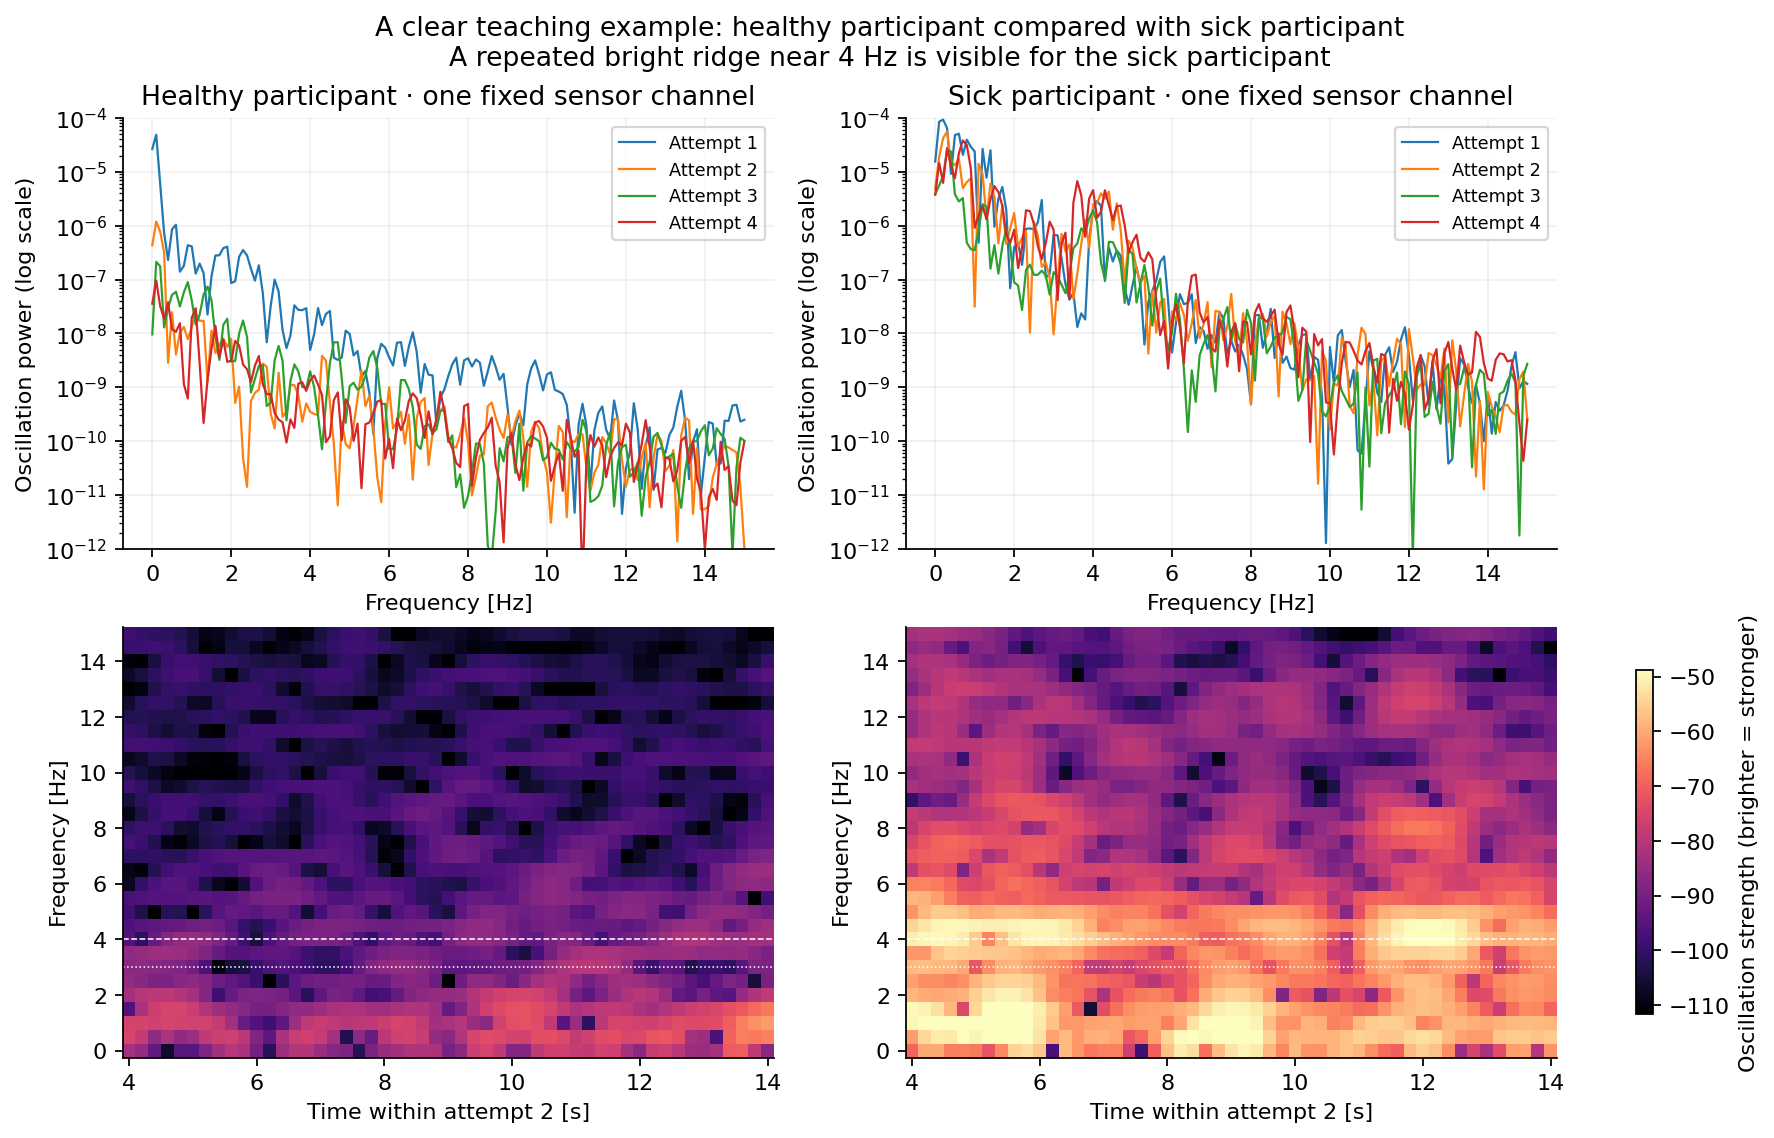

,patient_id,iteration,tremor_rms,peak_hz,centroid_hz
0,992612,1,0.000168,4.2,6.005882
1,992612,2,0.000051,4.3,6.770155
2,992612,3,0.000071,4.7,5.830950
3,992612,4,0.000046,4.1,6.886911
4,ILHC-BZCP,1,0.001015,4.1,4.544262
5,ILHC-BZCP,2,0.001522,4.4,4.471600
6,ILHC-BZCP,3,0.000815,4.0,4.655219
7,ILHC-BZCP,4,0.001589,4.0,4.564911


In [8]:
figure("08_illustrative_tremor_case")
display(table("illustrative_case_channel10")[["patient_id", "iteration", "tremor_rms", "peak_hz", "centroid_hz"]])

## 9. What happens across all people?
The following scatter plots show **one point per person**, using the mean of assessable hands. Blue dots are people in the healthy/control recruitment group and orange dots are people in the sick group. This descriptive plot keeps all control-recruitment records; the classifier in the next section uses only the 76 screened healthy people and uses the maximum hand value, so its sample and aggregation differ.

The numerical cohort medians below also use one mean-of-hands value per participant. Keeping the denominator explicit avoids treating hundreds of windows as hundreds of independent people.

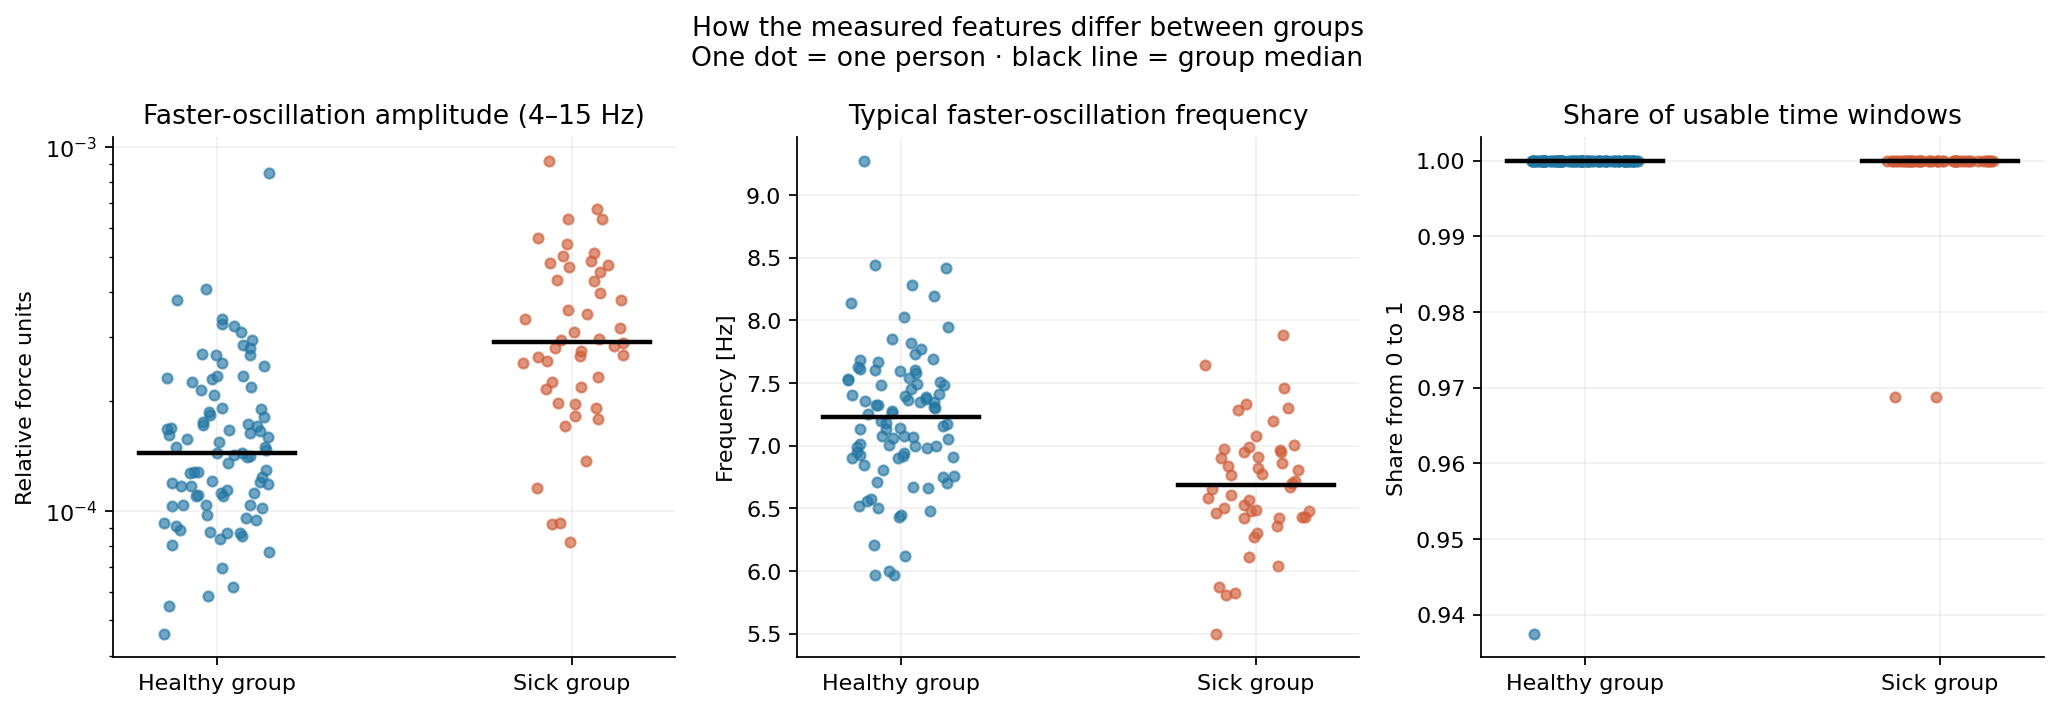

,Time interval,People,Median faster-oscillation amplitude,Median slow-change amplitude,Group
0,primary: 3–8 and 8–13 s,48,0.000292,0.003518,Sick group
1,primary: 3–8 and 8–13 s,90,0.000144,0.000692,Healthy group
2,early: 3–8 s,48,0.000348,0.004900,Sick group
3,early: 3–8 s,90,0.000150,0.000837,Healthy group
4,late: 8–13 s,48,0.000253,0.002030,Sick group
5,late: 8–13 s,90,0.000125,0.000504,Healthy group


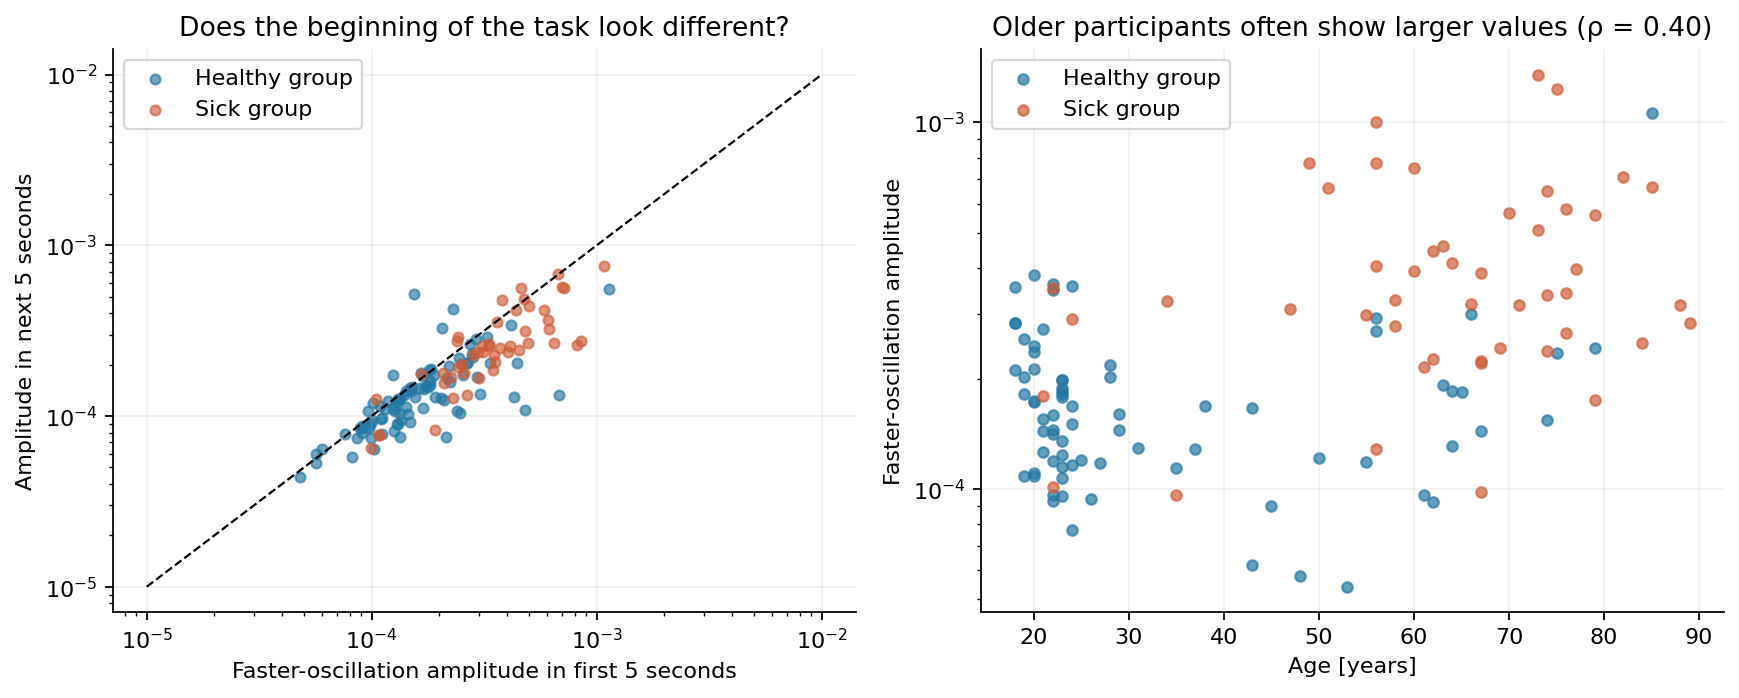

metric                  sensitivity_3_rms  sensitivity_3p5_rms  tremor_rms
Group         window_s                                                    
Healthy group 3                  0.000173             0.000152    0.000142
              5                  0.000176             0.000155    0.000144
              10                 0.000168             0.000152    0.000141
Sick group    3                  0.000360             0.000316    0.000291
              5                  0.000356             0.000318    0.000292
              10                 0.000373             0.000309    0.000269

In [9]:
figure("05_cohort_features")
transient = table("transient_sensitivity").copy()
transient["Group"] = transient.cohort.map({"reference":"Healthy group", "patient":"Sick group"})
display(transient.drop(columns="cohort").rename(columns={"interval":"Time interval", "people":"People", "median_tremor_rms":"Median faster-oscillation amplitude", "median_slow_rms":"Median slow-change amplitude"}))
figure("07_transients_and_age")
band = table("band_window_sensitivity").copy()
band["Group"] = band.cohort.map({"reference":"Healthy group", "patient":"Sick group"})
display(band.pivot_table(index=["Group", "window_s"], columns="metric", values="median"))

Primary median faster-oscillation amplitude is about **0.000292** in the sick group versus **0.000144** in the healthy/control recruitment group, but the distributions overlap. Removing early windows reduces these medians to about **0.000253** and **0.000125**. Slow-band variation also falls substantially in the late windows.

This demonstrates sensitivity to when we measure. It does not prove the early/late difference is entirely voluntary. Cutoff sensitivity is also visible: including 3–4 Hz increases the RMS, especially in the sick group. Window-length sensitivity changes both frequency bins and the time intervals averaged.

## 10. Can these measurements predict healthy versus sick?
This simple baseline is preparation for the next classification task. It predicts **sick-group versus screened-healthy-group membership**, not a medical diagnosis.

- One feature: maximum assessable-hand RMS in 4–15 Hz; hands require at least four valid windows.
- Five stratified participant folds, fixed seed 20261010. No person or their repeated sessions appears in both training and test for a fold.
- Each training split chooses the threshold and its direction that maximize training balanced accuracy. That rule predicts the held-out participants.
- Age alone is evaluated on the **same people and folds** as a confounding check. No threshold is recommended for clinical use.
- Sensitivity is the fraction of sick-group participants correctly classified; specificity is the fraction of screened healthy participants correctly classified. Balanced accuracy is their mean.

The raw-feature AUC is descriptive and is not an independent test of a fitted diagnostic model. The bootstrap interval resamples fixed out-of-fold predictions and understates some training/split uncertainty.

In [10]:
metrics = table("baseline_metrics").merge(table("baseline_bootstrap_intervals"), on="feature")
metrics = metrics.rename(columns={"feature":"Measurement", "n":"People", "patients":"Sick people", "references":"Healthy people", "sensitivity":"Sick correctly identified", "specificity":"Healthy correctly identified", "balanced_accuracy":"Balanced accuracy", "balanced_accuracy_low":"Lower estimate", "balanced_accuracy_high":"Upper estimate"})
display(metrics[["Measurement", "People", "Sick people", "Healthy people", "Sick correctly identified", "Healthy correctly identified", "Balanced accuracy", "Lower estimate", "Upper estimate", "tp", "tn", "fp", "fn"]])
display(Markdown("**Late-window sensitivity (8–13 s only):**"))
late = table("late_baseline_metrics").rename(columns={"feature":"Measurement", "n":"People", "sensitivity":"Sick correctly identified", "specificity":"Healthy correctly identified", "balanced_accuracy":"Balanced accuracy"})
display(late[["Measurement", "People", "Sick correctly identified", "Healthy correctly identified", "Balanced accuracy"]])
age = table("age_summary")
age["Group"] = age.cohort.map({"reference":"Healthy/control recruitment group", "patient":"Sick group"})
display(age.drop(columns="cohort"))

,Measurement,People,Sick people,Healthy people,Sick correctly identified,Healthy correctly identified,Balanced accuracy,Lower estimate,Upper estimate,tp,tn,fp,fn
0,tremor_rms_max_hand,124,48,76,0.854167,0.75,0.802083,0.731360,0.870066,41,57,19,7
1,age,124,48,76,0.854167,0.75,0.802083,0.729701,0.871738,41,57,19,7


**Late-window sensitivity (8–13 s only):**

,Measurement,People,Sick correctly identified,Healthy correctly identified,Balanced accuracy
0,tremor_rms_max_hand,124,0.708333,0.776316,0.742325
1,age,124,0.854167,0.750000,0.802083


,count,median,min,max,Group
0,48,66.5,21,89,Sick group
1,90,24.0,18,85,Healthy/control recruitment group


The amplitude rule and the age-only rule both achieve **80.2% balanced accuracy**, with different possible errors despite identical aggregate counts. The approximate amplitude interval is **73.1–87.0%**, conditional on these held-out predictions. Using late windows only lowers the amplitude rule's balanced accuracy to **74.2%**, while age remains **80.2%**.

Median age is **66.5 years** in the sick group and **24 years** in the full healthy/control recruitment group. Age and amplitude are associated (Spearman ρ ≈ 0.40). In addition, the two recruitment groups use different scenario IDs and collection periods. These results cannot establish that the classifier learned disease-specific involuntary tremor. No spectrogram-image classifier is trained; the present task produces its input measurements and visualization protocol.

## 11. What to present, and what to do next
**What is complete:** cohort-wide feature extraction, per-hand missing-evidence handling, 3/5/10 s comparisons, paired spectrograms, a visible-oscillation example, sensitivity analyses, and an exploratory decision-rule baseline.

**What remains uncertain:** sensor calibration/contact floor, physical finger mapping, acquisition firmware/rate, exact equivalence of the game versions, clinical tremor labels, and whether differences survive age/protocol control.

A defensible next experiment is to verify labels and game settings, obtain unloaded-sensor measurements and supervised hand-use annotations, then evaluate a small prespecified feature model on comparable or adjusted cohorts with participant-separated validation. A later spectrogram model must use the same separation; image patches from one person cannot cross training/test boundaries.

For your spoken explanation, follow **signal → frequency bands → RMS/frequency features → hand-use checks → person-level comparison → limitations**. The accompanying `GUIDE.md` walks through this sequence and includes answers to likely teacher questions.

## Sources and reproducibility
- [Original RehaPiano study](https://www.mdpi.com/1424-8220/20/3/663): device and action-tremor context, not validation of this dataset.
- [Force-control experiment](https://pmc.ncbi.nlm.nih.gov/articles/PMC3202062/): low-frequency force fluctuations can have multiple causes; motivates caution about attribution.
- [SciPy periodogram](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.periodogram.html) and [signal-processing API](https://docs.scipy.org/doc/scipy/reference/signal.html): PSD/filter/resampling definitions. Installed versions are recorded below.
- [Provided questionnaire](https://docs.google.com/spreadsheets/d/10DFfaDRp2afH05lRCV9hch8r1qXtUcts4Swd8LS5j1A/edit): control/reference-group self-report screening.
- [Provided introductory document](https://docs.google.com/document/d/10up07CQwDuW3CaO1pDwUTzbFczxR9u2v/edit) and [research protocol](https://docs.google.com/document/d/1y_hu1cCtswkxCB3QQQJb6Cm-RbaZ0ONS/edit): context and study design. Retrieved 10 October 2026.
- [ESTEN page supplied with the task](https://esten.solutions/blog/rehapiano-by-esten): opened, but the accessible page body did not provide quantitative analysis details.
- Local evidence: `task_1.ipynb`, `fourier_exact_force.ipynb`, `dataset_full_analysis.ipynb`, `data_preprocessing 1.ipynb`, converter source, cohort indices, raw packets and archived step configuration.

The input documents are evidence, not instructions to contact people or change external records. No email was sent and no cloud files were modified.

In [11]:
display(pd.Series(summary["versions"], name="version").to_frame())
assert len(table("participant_features")) == 138
assert not table("participant_features").patient_id.duplicated().any()
assert summary["processing_errors"] == 0
assert features[["patient_id", "hand"]].duplicated().sum() == 0
assert all(features.valid_windows >= 4)
print("Export integrity checks passed. Source recordings were not modified.")

,version
python,3.9.6
numpy,2.0.2
pandas,2.3.3
scipy,1.13.1
matplotlib,3.9.4


Export integrity checks passed. Source recordings were not modified.
